In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Load the dataset
df = pd.read_csv("/content/creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

Dataset loaded successfully!
Dataset shape: (284807, 31)

First 5 rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.7

In [ ]:

# Find the categories
print("Categories:", df["Class"].unique())

# Find the count of each category
print("\nCategory counts:")
print(df["Class"].value_counts())

# Find the percentage of each category
print("\nCategory percentages:")
print(df["Class"].value_counts(normalize=True) * 100)


Categories: [0 1]

Category counts:
Class
0    284315
1       492
Name: count, dtype: int64

Category percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [ ]:
# Features: all columns except Class
X = df.drop("Class", axis=1)

# Target: Class column
y = df["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (284807, 30)
Target shape: (284807,)

Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nFraud cases in training data:", int(y_train.sum()))
print("Fraud cases in testing data:", int(y_test.sum()))

Training data: (227845, 30)
Testing data: (56962, 30)

Fraud cases in training data: 394
Fraud cases in testing data: 98


In [ ]:
model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest model...")

model.fit(X_train, y_train)

print("Model training completed successfully!")

Training Random Forest model...
Model training completed successfully!


In [ ]:

# Predict transaction classes
y_pred = model.predict(X_test)

# Predict fraud probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Display actual and predicted labels
print("Actual labels:")
print(y_test.head(20))

print("Predicted labels:")
print(y_pred[:20])


Actual labels:
263020    0
11378     0
147283    0
219439    0
36939     0
243438    0
259448    0
43800     0
66742     0
66499     0
83371     0
12890     0
81804     0
192849    0
91888     0
248680    0
59051     0
8336      0
118398    0
224464    0
Name: Class, dtype: int64
Predicted labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


Confusion Matrix:
[[56861     3]
 [   26    72]]


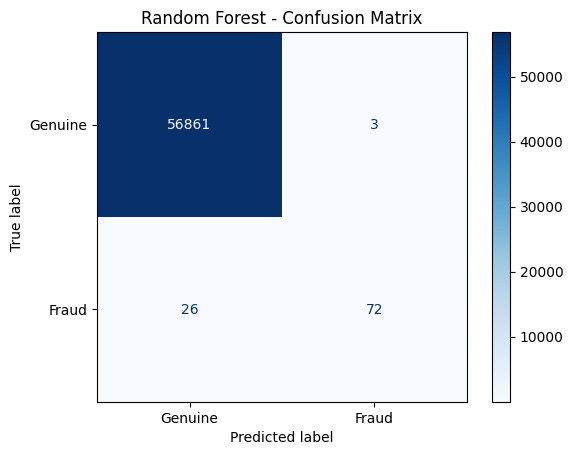

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [ ]:
precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

MODEL EVALUATION RESULTS
------------------------
Precision : 0.9600
Recall    : 0.7347
F1-score  : 0.8324
ROC-AUC   : 0.9478

Detailed Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56864
       Fraud       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:

# Combine test data and predictions
results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = y_pred
results["Fraud_Probability"] = y_prob

# Select actual fraud transactions
actual_fraud = results[results["Actual"] == 1]

print("Total actual fraud cases:", len(actual_fraud))
print(actual_fraud[["Time", "Amount", "Actual", "Predicted", "Fraud_Probability"]].head(20))

# Count detected and missed fraud cases
print("Fraud detected:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 1)]))
print("Fraud missed:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 0)]))

# Save fraud transactions
actual_fraud.to_csv("actual_fraudulent_test_transactions.csv", index=True)
print("File saved successfully!")


Total actual fraud cases: 98
            Time  Amount  Actual  Predicted  Fraud_Probability
77348    57007.0    0.01       1          1               0.99
102442   68207.0    1.00       1          1               0.98
119781   75581.0  124.53       1          1               0.69
48094    43494.0   24.90       1          0               0.30
42958    41313.0    9.99       1          1               0.89
52584    45541.0    1.00       1          1               0.90
204064  135095.0  345.00       1          1               0.77
151519   95628.0    1.63       1          1               0.99
203324  134766.0    1.00       1          1               0.81
141260   84204.0  512.25       1          1               0.97
70589    53937.0  261.87       1          0               0.36
14170    25198.0   99.99       1          0               0.32
222133  142840.0  144.80       1          1               0.82
153835  100298.0    1.00       1          1               0.93
14197    25231.0   99.99  

Top 10 Important Features:
V14    0.188221
V10    0.107930
V12    0.096627
V4     0.094597
V17    0.091457
V3     0.068918
V11    0.056226
V16    0.038522
V2     0.037497
V9     0.025752
dtype: float64


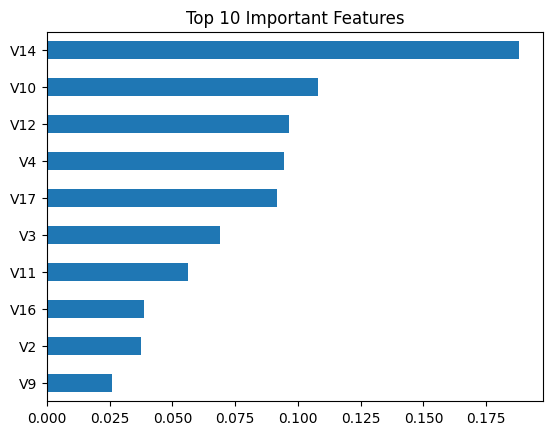

In [ ]:

# Get feature importance
importance = pd.Series(model.feature_importances_, index=X.columns)

# Display top 10 important features
top10 = importance.nlargest(10)
print("Top 10 Important Features:")
print(top10)

# Plot the features
top10.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()


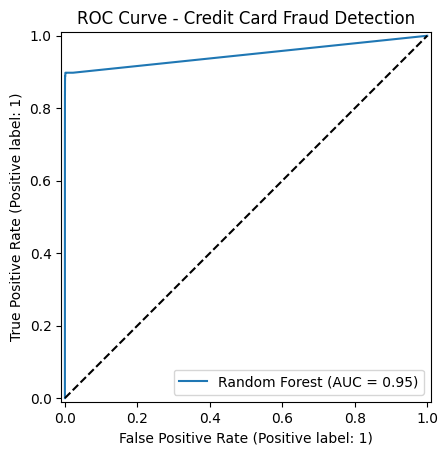

In [ ]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)

plt.title("ROC Curve - Credit Card Fraud Detection")
plt.plot([0, 1], [0, 1], "k--")
plt.show()